# YOLOv8-L Model Evaluation

Evaluation of the trained YOLOv8-S object detection model on the RDD2022 test dataset.

### Evaluation includes
- Overall detection metrics
- Per-class detection metrics
- AP@0.5 for each class
- mAP@0.5
- mAP@0.5:0.95
- Ground-truth vs prediction visualizations

## Setup

In [1]:
from pathlib import Path
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 

In [2]:
!pip install -q git+https://github.com/gracyy-rm/cv-toolkit.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
!git clone https://github.com/gracyy-rm/Road_damage_object_detection

Cloning into 'Road_damage_object_detection'...
remote: Enumerating objects: 88, done.
remote: Counting objects: 100% (88/88), done.
remote: Compressing objects: 100% (65/65), done.
remote: Total 88 (delta 43), reused 65 (delta 20), pack-reused 0 (from 0)
Receiving objects: 100% (88/88), 9.13 MiB | 27.50 MiB/s, done.
Resolving deltas: 100% (43/43), done.


In [4]:
!pwd

/kaggle/working


In [5]:
import os
os.chdir("/kaggle/working/Road_damage_object_detection")

In [6]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.9/47.9 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 32.2 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 103.8/103.8 kB 3.6 MB/s eta 0:00:00


In [7]:
import cvcore 
from cvcore.metric_operations.detection import DatasetEvaluator, ImageEvaluator
from src.inference import ModelInference

from ultralytics import YOLO


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## INference on yolo-l

In [8]:
model_path_yolov8L = "/kaggle/input/models/gracyyadav79/yolov8-l/pytorch/default/1/best.pt"

test_images_dir= Path("/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/test/images")

pred_json_dir = Path("/kaggle/working/predictions/yolo_L")
pred_json_dir.mkdir(parents=True, exist_ok=True)

In [9]:
# yolo_L_infer = ModelInference(model_path = model_path_yolov8L)

In [10]:
# yolo_L_infer.predict_dataset(images_dir=test_images_dir,output_dir=pred_json_dir)

## Paths

In [11]:
GT_DIR = Path("/kaggle/input/datasets/gracyyadav79/annotations-pred/test_jsons/gt/test")
PRED_DIR = Path("/kaggle/input/datasets/gracyyadav79/yolov8-l-pred/yolo_L")

OUTPUT_DIR = Path("/kaggle/working/yolov8L_evaluation")
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)

## Verify Evaluation Files

In [12]:
gt_files = sorted(GT_DIR.glob("*.json"))
pred_files = sorted(PRED_DIR.glob("*json"))

print(f"Ground-truth files :  {len(gt_files)}")
print(f"Predictions files : {len(pred_files)}")

Ground-truth files :  5758
Predictions files : 5758


In [13]:
gt_ids = {path.stem for path in gt_files}
pred_ids = {path.stem for path in pred_files}

print(f"GT files without predictions : {len(gt_ids - pred_ids)}")
print(f"Predictions without GT        : {len(pred_ids - gt_ids)}")
print(f"Matched image files           : {len(gt_ids & pred_ids)}")

GT files without predictions : 0
Predictions without GT        : 0
Matched image files           : 5758


##  Single-Image Evaluation

`ImageEvaluator` is used to inspect the detection performance of an individual image.

The evaluation includes:

- Ground-truth annotations
- Model predictions
- IoU-based matching
- TP, FP and FN
- Precision, Recall and F1-score
- Mean IoU
- Per-class detection metrics

In [14]:
image_id = gt_files[0].stem

image_evaluator = ImageEvaluator(
    gt_path_or_data=GT_DIR / f"{image_id}.json",
    pred_path_or_data=PRED_DIR / f"{image_id}.json",
    threshold = 0.5
)

print(f"Image ID: {image_id}")

Image ID: China_Drone_000008


In [15]:
image_evaluator.get_stat(
    confidence_thresholds=[0.1, 0.2, 0.3, 0.4,0.5,0.6,0.7,0.8,0.9],
    threshold=0.5,
    metric_type="ios",
    return_stat=True
)


SINGLE-IMAGE OVERALL DETECTION METRICS (IOS@0.5)

+--------------+------+---------------+------+------+------+-------------+----------+------+------------+
|   Confidence |   GT |   Predictions |   TP |   FP |   FN |   Precision |   Recall |   F1 |   Mean IOS |
+==============+======+===============+======+======+======+=============+==========+======+============+
|          0.1 |    1 |             1 |    1 |    0 |    0 |           1 |        1 |    1 |          1 |
+--------------+------+---------------+------+------+------+-------------+----------+------+------------+
|          0.2 |    1 |             1 |    1 |    0 |    0 |           1 |        1 |    1 |          1 |
+--------------+------+---------------+------+------+------+-------------+----------+------+------------+
|          0.3 |    1 |             1 |    1 |    0 |    0 |           1 |        1 |    1 |          1 |
+--------------+------+---------------+------+------+------+-------------+----------+------+---------

### Checking instance for single image 

In [16]:
# 1. Verify Ground Truth and Prediction JSON data are loaded
print("GT Data loaded:", bool(image_evaluator.gt_data))
print("GT Annotations count:", len(image_evaluator.gt_data.get("annotations", [])))
print("Predictions count:", len(image_evaluator.pred_data.get("predictions", [])))

# 2. Verify Class Label Mapping is built
print("Label Mapping:", image_evaluator.label_mapping)

# 3. Verify Evaluation Results are stored (after calling get_stat)
image_evaluator.get_stat(return_stat=False)

if image_evaluator.results is not None:
    print("Evaluation results are stored in memory!")
    print("Overall metrics :", image_evaluator.results["overall"])
    print("Per-class metrics :", image_evaluator.results["per_class"])
else:
    print("Results are empty!")

GT Data loaded: True
GT Annotations count: 1
Predictions count: 1
Label Mapping: {1: 'transverse crack'}
Evaluation results are stored in memory!
Overall metrics : [{'gt_count': 1, 'prediction_count': 1, 'tp': 1, 'fp': 0, 'fn': 0, 'precision': 1.0, 'recall': 1.0, 'f1_score': 1.0, 'mean_score': 1.0, 'metric_type': 'IOS', 'confidence_threshold': 0.25, 'matched_scores': [1.0]}, {'gt_count': 1, 'prediction_count': 0, 'tp': 0, 'fp': 0, 'fn': 1, 'precision': 0.0, 'recall': 0.0, 'f1_score': 0.0, 'mean_score': 0.0, 'metric_type': 'IOS', 'confidence_threshold': 0.5, 'matched_scores': []}, {'gt_count': 1, 'prediction_count': 0, 'tp': 0, 'fp': 0, 'fn': 1, 'precision': 0.0, 'recall': 0.0, 'f1_score': 0.0, 'mean_score': 0.0, 'metric_type': 'IOS', 'confidence_threshold': 0.75, 'matched_scores': []}]
Per-class metrics : [{'gt_count': 1, 'prediction_count': 1, 'tp': 1, 'fp': 0, 'fn': 0, 'precision': 1.0, 'recall': 1.0, 'f1_score': 1.0, 'mean_score': 1.0, 'metric_type': 'IOS', 'class_id': 1, 'class_nam

## Ground Truth vs Predictions


--- Metrics for image:  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       1 |    1 |    0 |    0 |           1 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


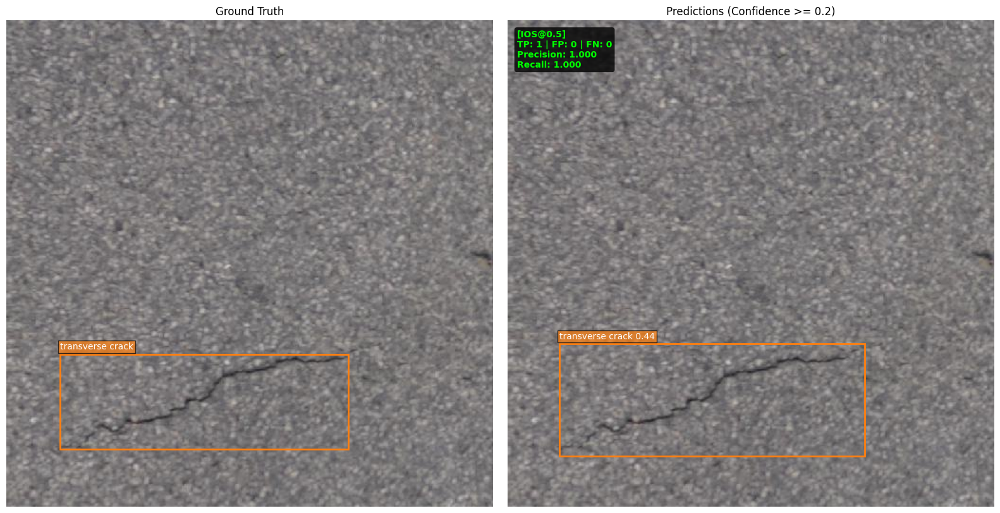

In [17]:
image_evaluator.plot(show=True,show_stats=True,confidence_threshold = 0.2)

### Additional Samples

Additional test images are randomly selected to inspect different prediction scenarios.


Image: United_States_001399

--- Metrics for image:  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       2 |    1 |    1 |    0 |         0.5 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


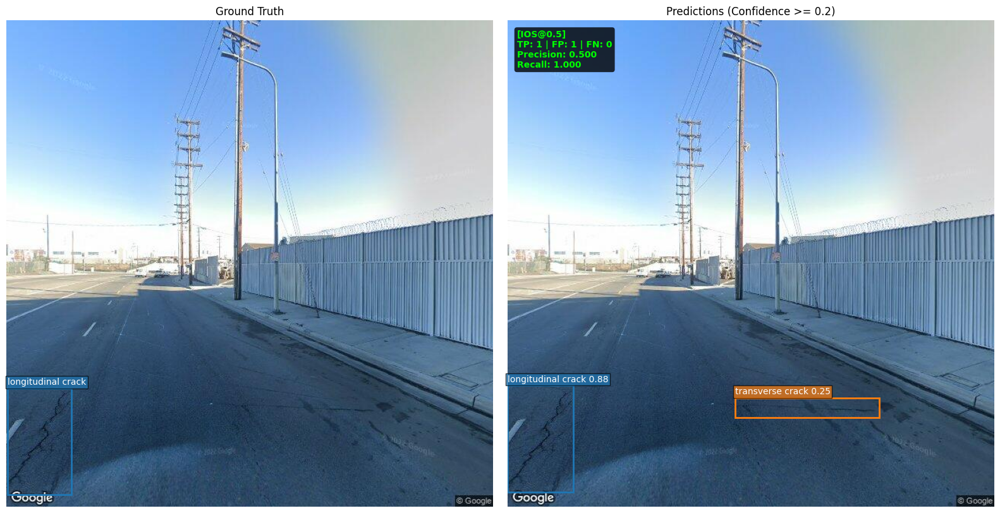


Image: Norway_008109

--- Metrics for image:  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    0 |       0 |    0 |    0 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


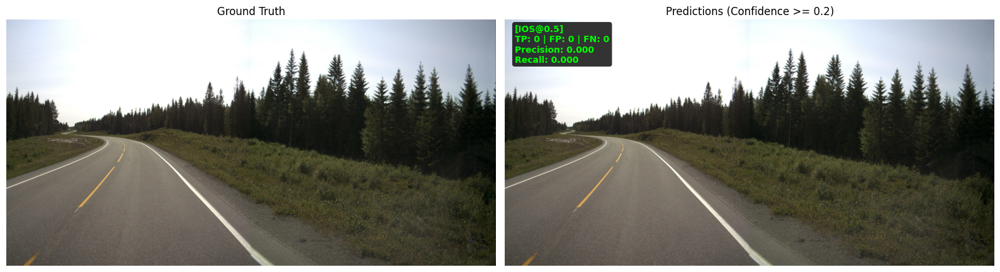


Image: Japan_002467

--- Metrics for image:  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    2 |       3 |    2 |    1 |    0 |      0.6667 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


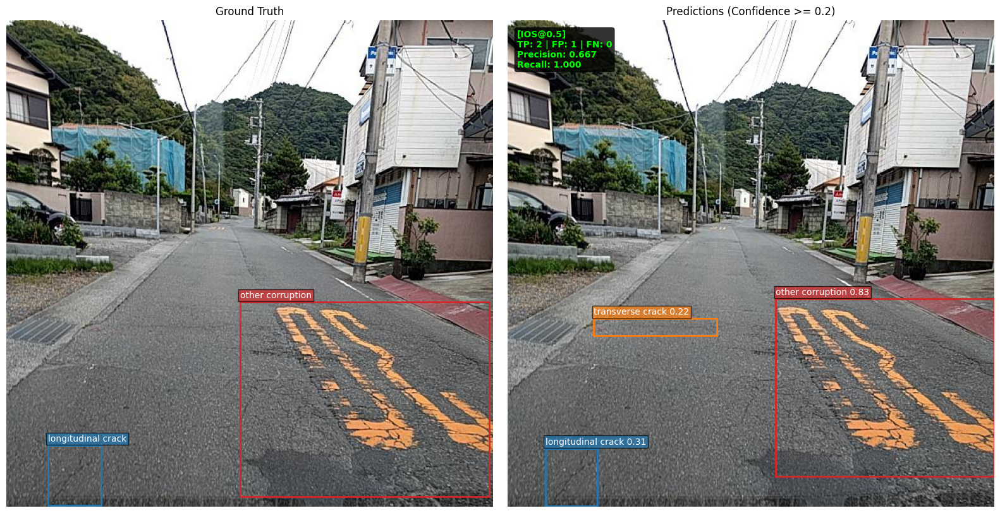

In [18]:
sample_image_ids = pd.Series(list(gt_ids & pred_ids)).sample(n=min(3, len(gt_ids & pred_ids)),random_state=42
).tolist()

for image_id in sample_image_ids:
    print(f"\nImage: {image_id}")

    evaluator = ImageEvaluator(
        gt_path_or_data=GT_DIR / f"{image_id}.json",
        pred_path_or_data=PRED_DIR / f"{image_id}.json",
        threshold=0.5,
        metric_type="ios"
    )

    evaluator.plot(
        confidence_threshold=0.2,
        show=True,
        show_stats = True
    )

In [19]:
image_evaluator.get_stat(confidence_thresholds=[0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9],metric_type="ios",threshold = 0.5, return_stat=True)


SINGLE-IMAGE OVERALL DETECTION METRICS (IOS@0.5)

+--------------+------+---------------+------+------+------+-------------+----------+------+------------+
|   Confidence |   GT |   Predictions |   TP |   FP |   FN |   Precision |   Recall |   F1 |   Mean IOS |
+==============+======+===============+======+======+======+=============+==========+======+============+
|          0.1 |    1 |             1 |    1 |    0 |    0 |           1 |        1 |    1 |          1 |
+--------------+------+---------------+------+------+------+-------------+----------+------+------------+
|          0.2 |    1 |             1 |    1 |    0 |    0 |           1 |        1 |    1 |          1 |
+--------------+------+---------------+------+------+------+-------------+----------+------+------------+
|          0.3 |    1 |             1 |    1 |    0 |    0 |           1 |        1 |    1 |          1 |
+--------------+------+---------------+------+------+------+-------------+----------+------+---------

## 5. Dataset-Level Evaluation

`DatasetEvaluator` aggregates predictions across the complete evaluation dataset.

This provides the final model-level detection metrics.

In [20]:
dataset_evaluator = DatasetEvaluator(
    gt_dir=GT_DIR,
    pred_dir=PRED_DIR,
    metric_type="ios",
)

In [21]:
dataset_evaluator.get_stat(
    confidence_thresholds=[0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9],
    return_stat=True,
    metric_type = "ios",
    threshold=0.5
    
)

Evaluating (IOS): 100%|██████████| 5758/5758 [00:48<00:00, 119.94img/s]



DATASET-LEVEL OVERALL METRICS (IOS@0.5)

+--------------+------+---------------+------+------+------+-------------+----------+--------+------------+
|   Confidence |   GT |   Predictions |   TP |   FP |   FN |   Precision |   Recall |     F1 |   Mean IOS |
+==============+======+===============+======+======+======+=============+==========+========+============+
|          0.1 | 9675 |         13970 | 7722 | 6248 | 1953 |      0.5528 |   0.7981 | 0.6532 |     0.9456 |
+--------------+------+---------------+------+------+------+-------------+----------+--------+------------+
|          0.2 | 9675 |          9803 | 6850 | 2953 | 2825 |      0.6988 |   0.708  | 0.7034 |     0.9501 |
+--------------+------+---------------+------+------+------+-------------+----------+--------+------------+
|          0.3 | 9675 |          7641 | 5995 | 1646 | 3680 |      0.7846 |   0.6196 | 0.6924 |     0.954  |
+--------------+------+---------------+------+------+------+-------------+----------+--------+

### Checking the dataset evaluator instacne 

In [22]:
print("total dataset images", len(dataset_evaluator.all_image_object))

total dataset images 5758


In [23]:
print("dataset metrics",dataset_evaluator.results)
print("overall resutls", dataset_evaluator.overall_df)
print("per_class_table",dataset_evaluator.per_class_df)
print("AP score",dataset_evaluator.ap_df)
print("MAP_50 score",dataset_evaluator.results["map_50"])
print("MAP_50:95 score",dataset_evaluator.results["map_50_95"])

dataset metrics {'overall': [{'gt_count': 9675, 'prediction_count': 13970, 'tp': 7722, 'fp': 6248, 'fn': 1953, 'precision': 0.552755905511811, 'recall': 0.7981395348837209, 'f1_score': 0.653161344893212, 'mean_score': 0.9456289599884191, 'metric_type': 'IOS', 'confidence_threshold': 0.1}, {'gt_count': 9675, 'prediction_count': 9803, 'tp': 6850, 'fp': 2953, 'fn': 2825, 'precision': 0.6987656839742936, 'recall': 0.7080103359173127, 'f1_score': 0.7033576342540301, 'mean_score': 0.95012883751979, 'metric_type': 'IOS', 'confidence_threshold': 0.2}, {'gt_count': 9675, 'prediction_count': 7641, 'tp': 5995, 'fp': 1646, 'fn': 3680, 'precision': 0.7845831697421803, 'recall': 0.6196382428940569, 'f1_score': 0.6924231924231924, 'mean_score': 0.9540329220245715, 'metric_type': 'IOS', 'confidence_threshold': 0.3}, {'gt_count': 9675, 'prediction_count': 6004, 'tp': 5090, 'fp': 914, 'fn': 4585, 'precision': 0.8477681545636242, 'recall': 0.5260981912144703, 'f1_score': 0.6492761017922061, 'mean_score':

In [24]:
sample_image = dataset_evaluator.all_image_object["China_Drone_000017"]
print(sample_image.results)

{'overall': [{'gt_count': 1, 'prediction_count': 2, 'tp': 1, 'fp': 1, 'fn': 0, 'precision': 0.5, 'recall': 1.0, 'f1_score': 0.6666666666666666, 'mean_score': 0.9057849493487072, 'metric_type': 'IOS', 'confidence_threshold': 0.1, 'matched_scores': [0.9057849493487072]}, {'gt_count': 1, 'prediction_count': 1, 'tp': 1, 'fp': 0, 'fn': 0, 'precision': 1.0, 'recall': 1.0, 'f1_score': 1.0, 'mean_score': 0.9057849493487072, 'metric_type': 'IOS', 'confidence_threshold': 0.2, 'matched_scores': [0.9057849493487072]}, {'gt_count': 1, 'prediction_count': 1, 'tp': 1, 'fp': 0, 'fn': 0, 'precision': 1.0, 'recall': 1.0, 'f1_score': 1.0, 'mean_score': 0.9057849493487072, 'metric_type': 'IOS', 'confidence_threshold': 0.3, 'matched_scores': [0.9057849493487072]}, {'gt_count': 1, 'prediction_count': 1, 'tp': 1, 'fp': 0, 'fn': 0, 'precision': 1.0, 'recall': 1.0, 'f1_score': 1.0, 'mean_score': 0.9057849493487072, 'metric_type': 'IOS', 'confidence_threshold': 0.4, 'matched_scores': [0.9057849493487072]}, {'gt

In [25]:
dataset_metric_dir = Path("/kaggle/working/Yolov8L_evaluation")
dataset_metric_dir.mkdir(parents=True, exist_ok=True)

In [26]:
dataset_evaluator.overall_df.to_csv(dataset_metric_dir/"overall")

In [27]:
dataset_evaluator.per_class_df.to_csv(dataset_metric_dir/"per_class")

In [28]:
dataset_evaluator.ap_df.to_csv(dataset_metric_dir/"ap_df")

In [29]:
dataset_metric=dataset_evaluator.results

### Conditional filtering in the dataaset:
- This filtering can be doen on the basis of the following :
    - classes
    - model_confidenc_threshold
    - class_confidence_threshold
    - eq ( <,>,=>,etc)
    - metric 

In [30]:
# pothole : recall == 0.0 
potholes_fn = dataset_evaluator.filter(
    class_names=["pothole"],
    model_confidence_threshold=0.2,
    metric="fn",
    eq=">",
    class_confidence_threshold=0
)

print(f"cases where pothole was completely missed: {len(potholes_fn.all_image_object)}")

Filter matched 249 / 5758 images.
cases where pothole was completely missed: 249



--- Metrics for image: [Japan_000369]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    3 |       3 |    2 |    1 |    1 |      0.6667 |   0.6667 |
+------------------+------+---------+------+------+------+-------------+----------+


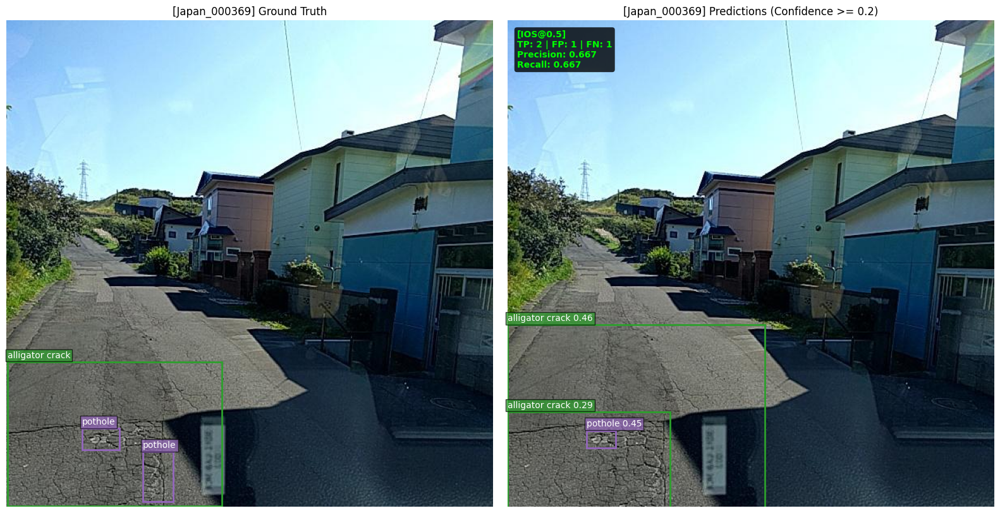


--- Metrics for image: [India_008499]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       1 |    0 |    1 |    1 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


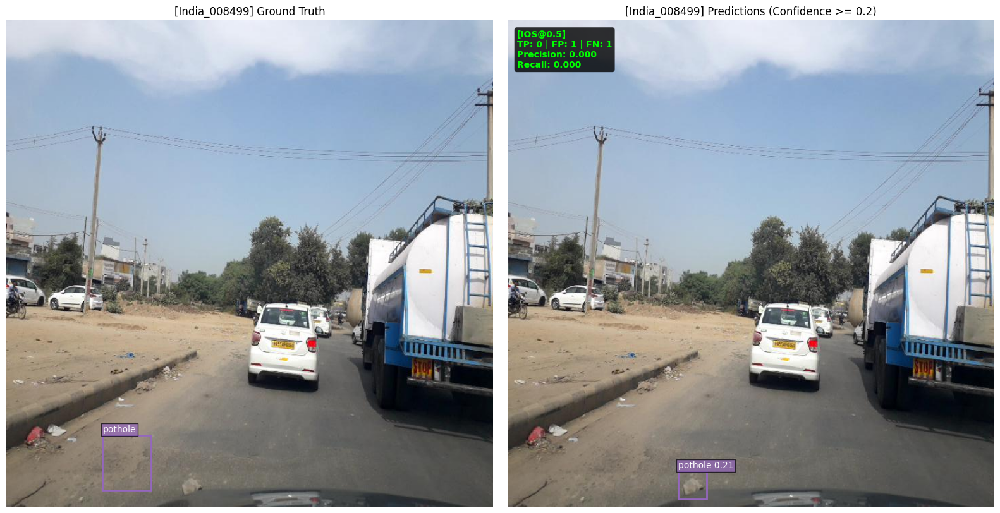


--- Metrics for image: [India_007647]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    2 |       2 |    1 |    1 |    1 |         0.5 |      0.5 |
+------------------+------+---------+------+------+------+-------------+----------+


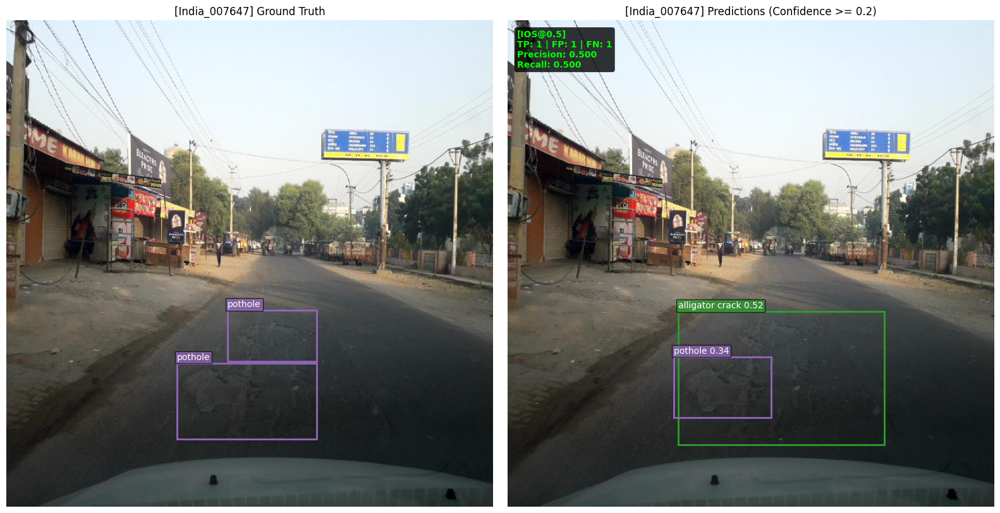


--- Metrics for image: [India_003312]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    2 |       2 |    1 |    1 |    1 |         0.5 |      0.5 |
+------------------+------+---------+------+------+------+-------------+----------+


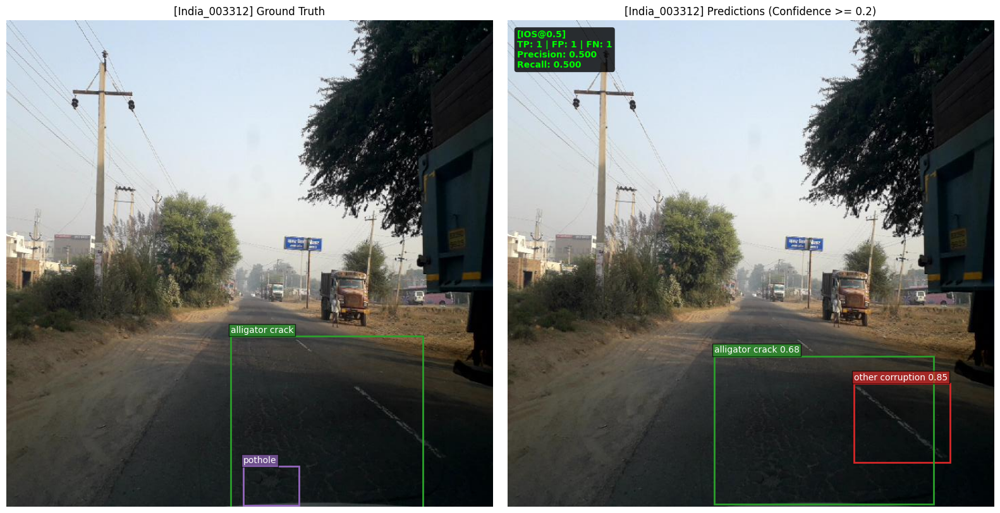


--- Metrics for image: [Norway_003567]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       0 |    0 |    0 |    1 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


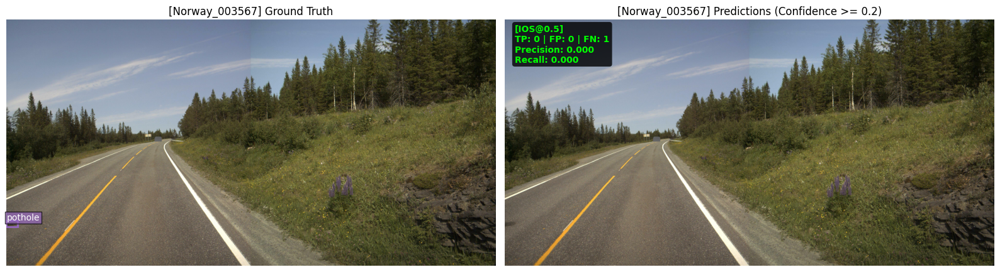

In [31]:
potholes_fn.plot(
    num_samples=5,
    confidence_threshold = 0.2,
    random_sample=True,
    model_confidence_threshold=0.2,
    show=True,
    show_stats=True
    )

Filter matched 167 / 5758 images.

--- Metrics for image: [Czech_003003] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       0 |    0 |    0 |    1 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


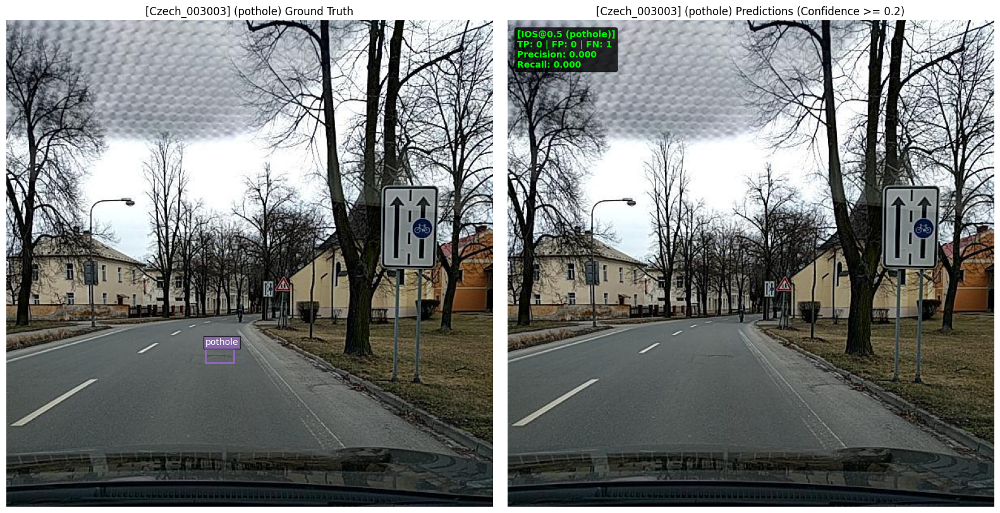


--- Metrics for image: [Japan_012791] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       0 |    0 |    0 |    1 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


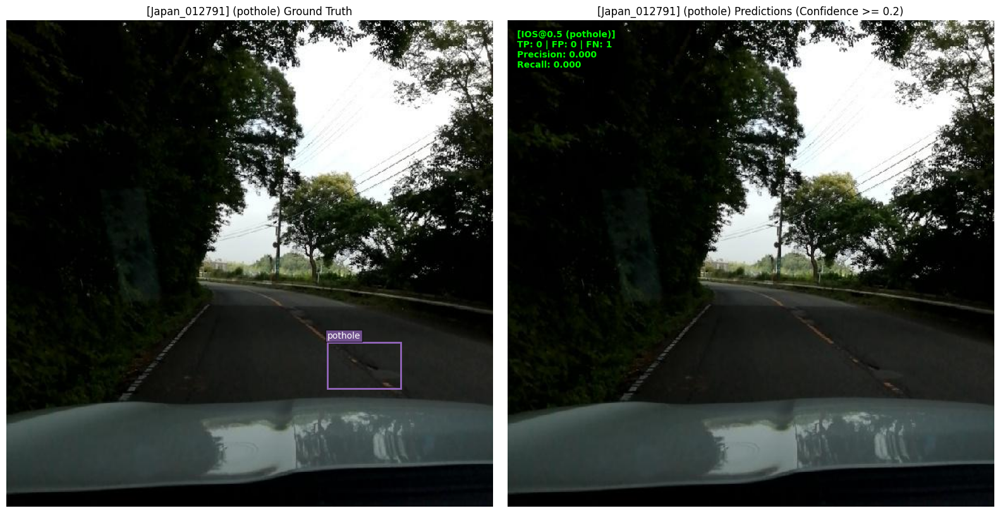


--- Metrics for image: [Norway_005693] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       0 |    0 |    0 |    1 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


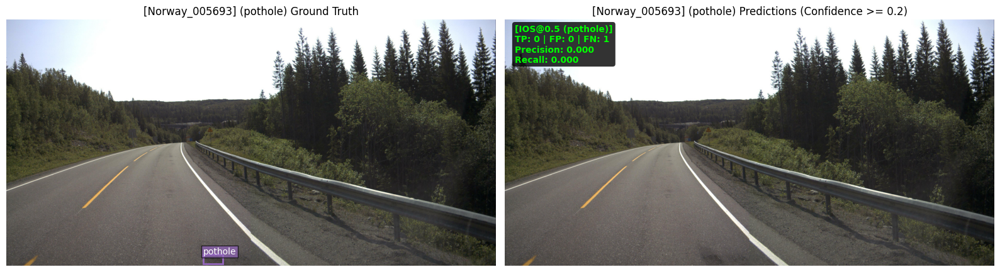


--- Metrics for image: [Japan_000605] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       0 |    0 |    0 |    1 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


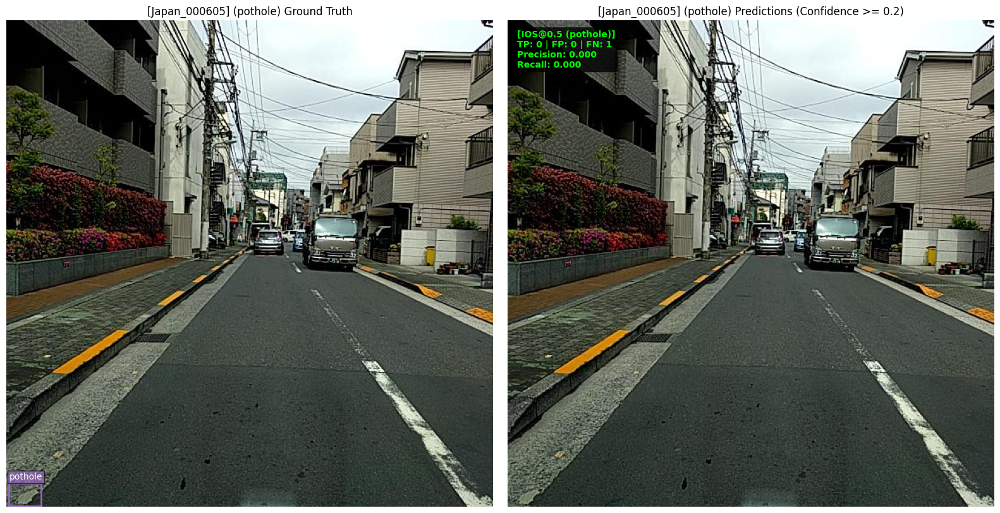


--- Metrics for image: [Czech_002501] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       0 |    0 |    0 |    1 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


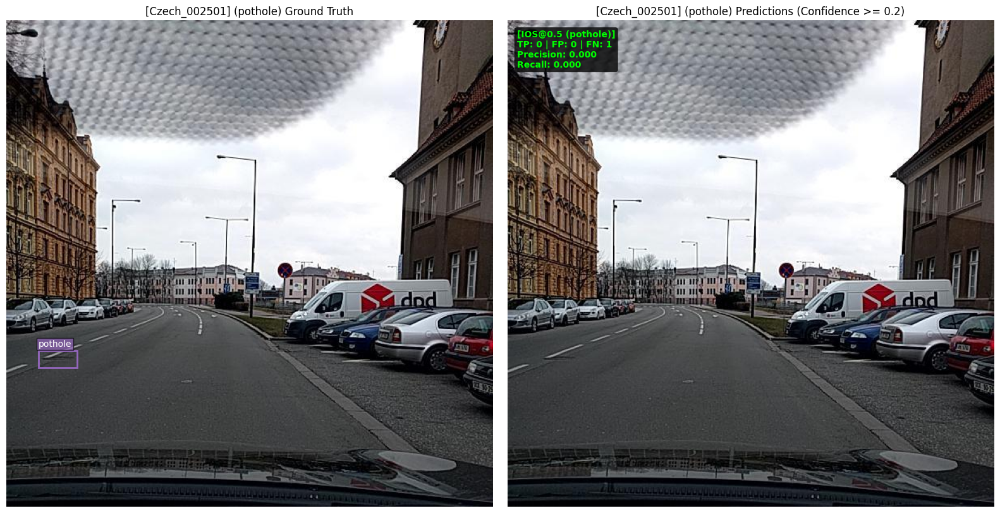


--- Metrics for image: [China_Drone_000383] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       0 |    0 |    0 |    1 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


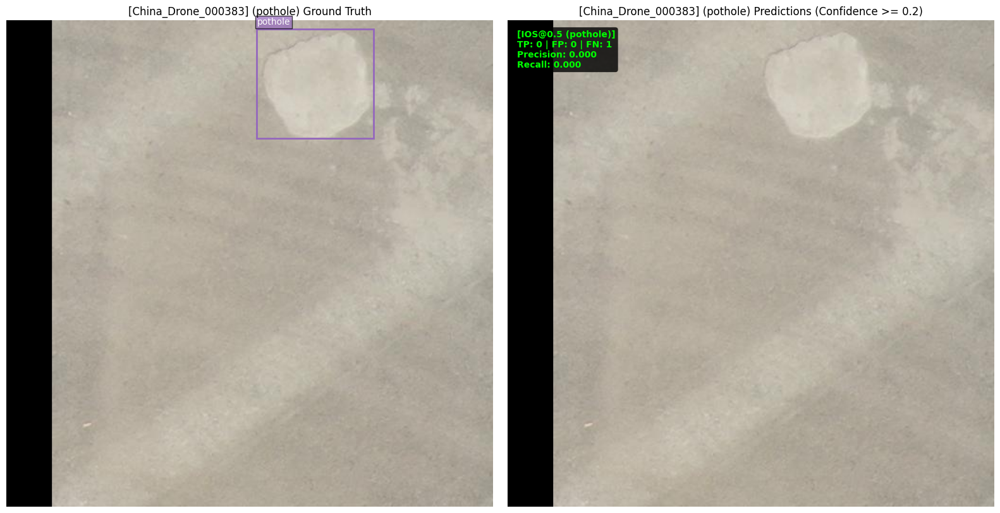


--- Metrics for image: [Japan_009961] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    3 |       1 |    1 |    0 |    2 |           1 |   0.3333 |
+------------------+------+---------+------+------+------+-------------+----------+


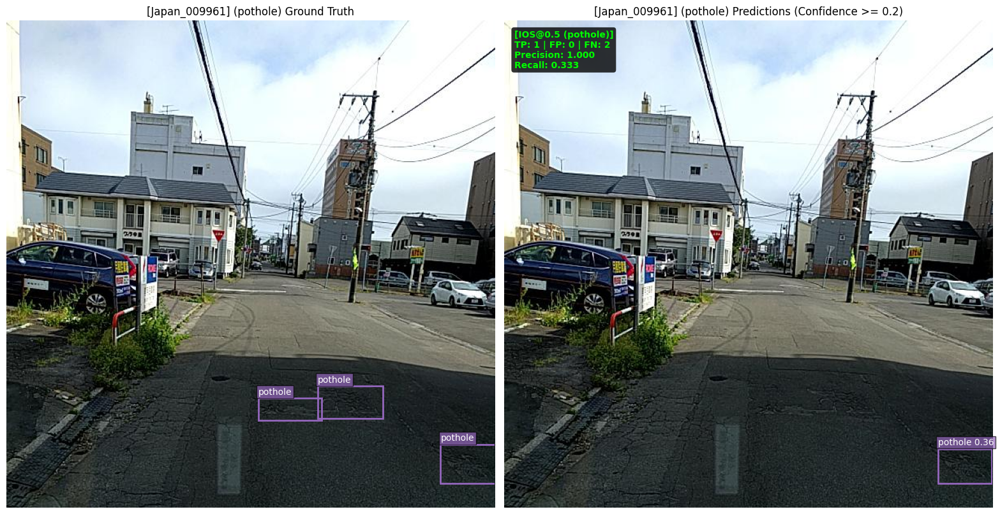


--- Metrics for image: [Norway_006526] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       0 |    0 |    0 |    1 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


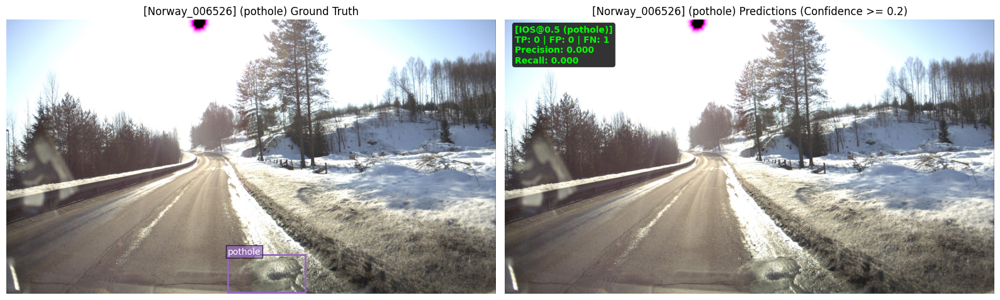


--- Metrics for image: [India_006920] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    3 |       1 |    1 |    0 |    2 |           1 |   0.3333 |
+------------------+------+---------+------+------+------+-------------+----------+


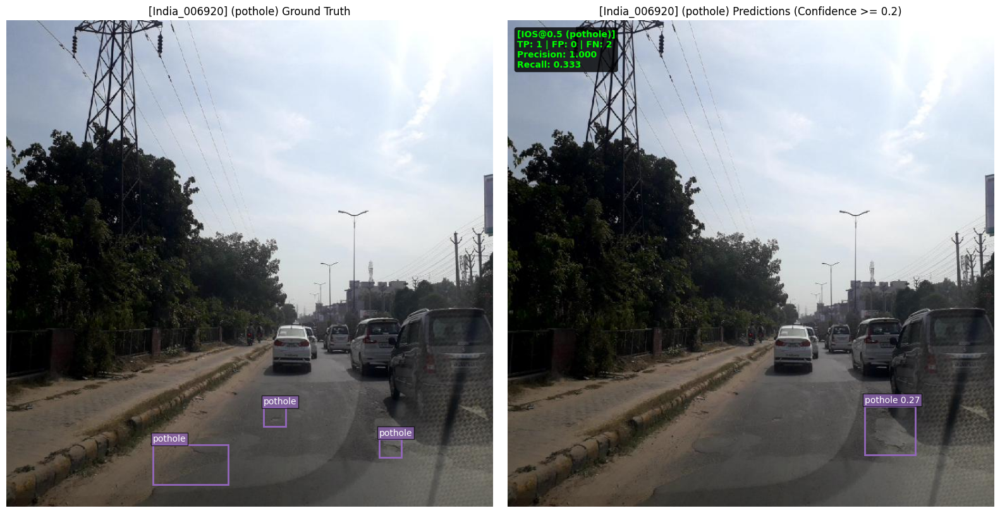


--- Metrics for image: [Japan_003859] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    2 |       0 |    0 |    0 |    2 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


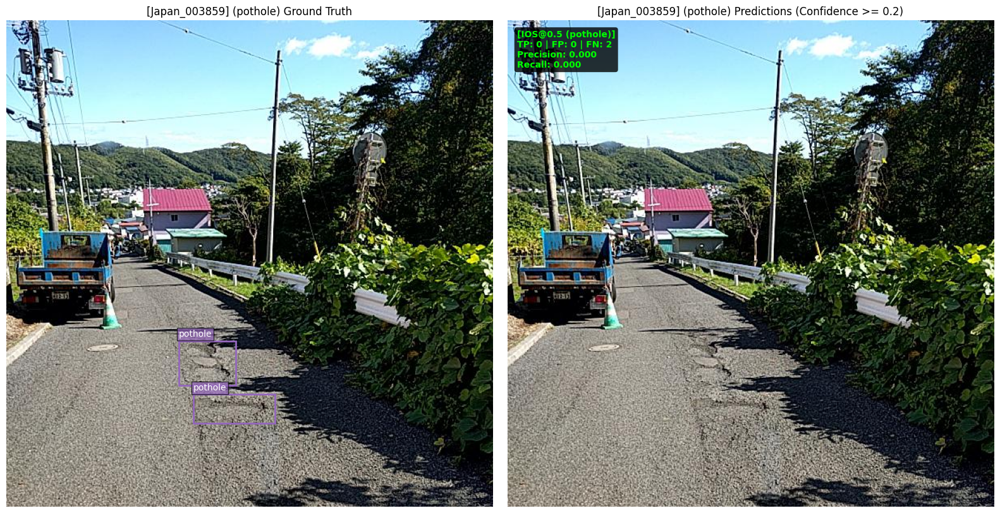

In [32]:
pothole_low_recall = dataset_evaluator.filter(
    class_names="pothole",
    model_confidence_threshold=0.2,
    metric="recall",
    eq="<",
    class_confidence_threshold=0.5,
)

pothole_low_recall.plot(
    num_samples=10,
    confidence_threshold=0.2,
    class_names="pothole",
    show_stats = True
)


Filter matched 1224 / 5758 images.

--- Metrics for image: [Japan_004165]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       3 |    1 |    2 |    0 |      0.3333 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


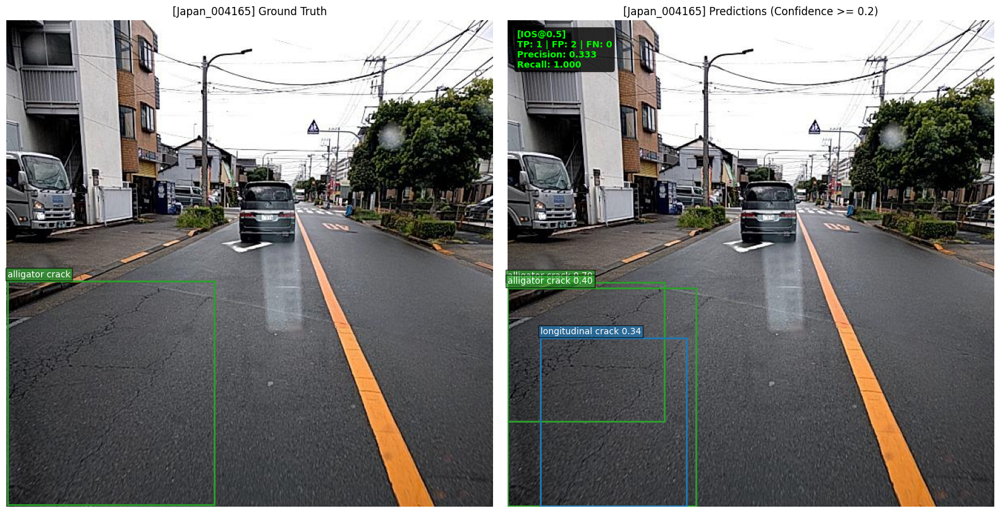


--- Metrics for image: [Japan_003155]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    2 |       3 |    2 |    1 |    0 |      0.6667 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


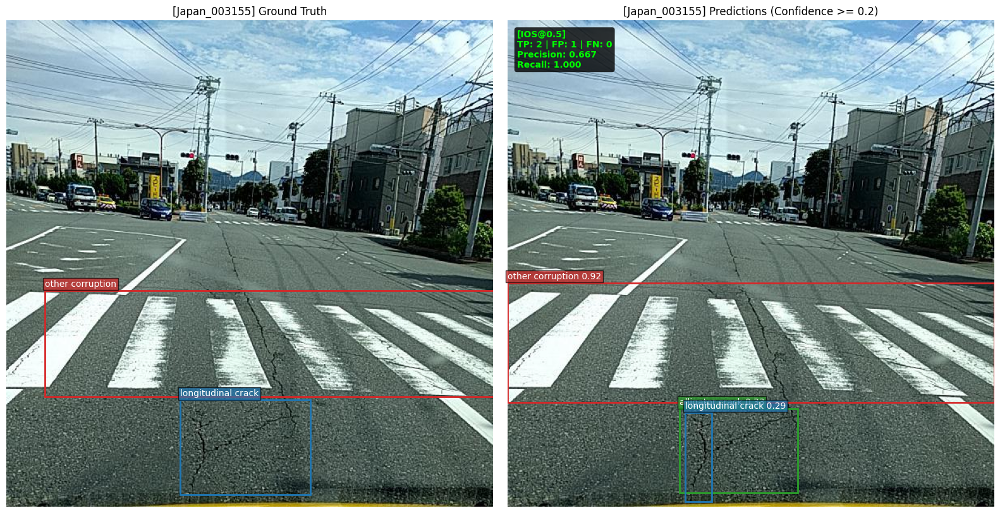


--- Metrics for image: [India_007387]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       2 |    1 |    1 |    0 |         0.5 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


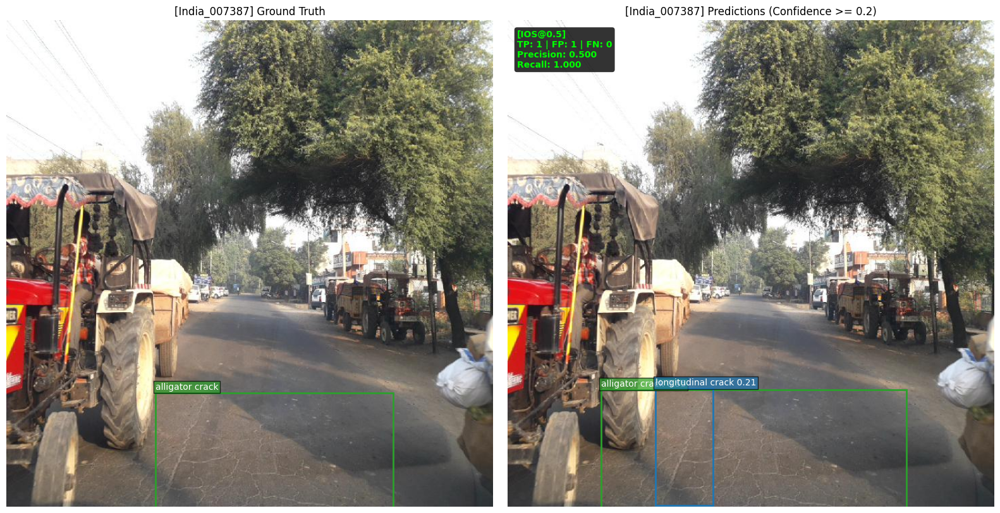


--- Metrics for image: [Japan_006908]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    7 |       7 |    4 |    3 |    3 |      0.5714 |   0.5714 |
+------------------+------+---------+------+------+------+-------------+----------+


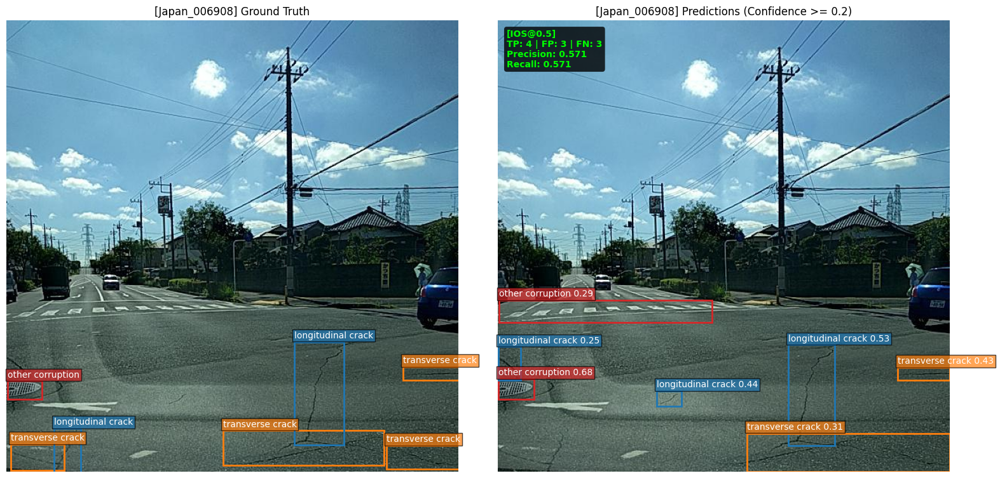


--- Metrics for image: [Japan_000404]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       4 |    1 |    3 |    0 |        0.25 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


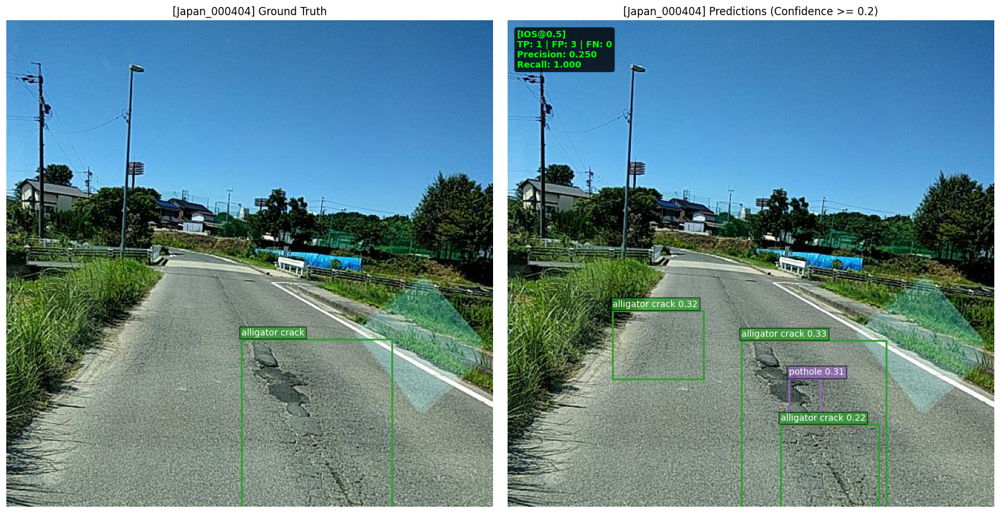


--- Metrics for image: [Czech_003277]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       2 |    0 |    2 |    1 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


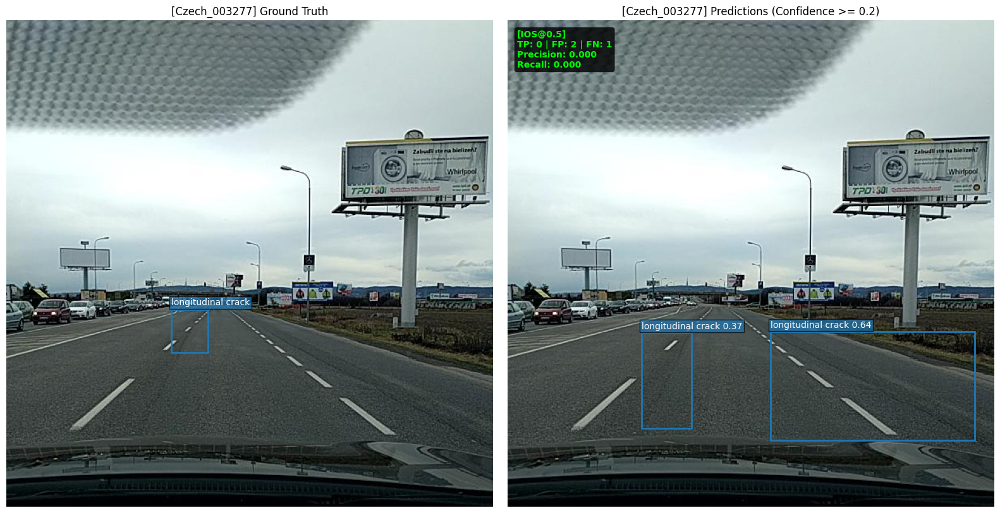


--- Metrics for image: [Japan_003448]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       2 |    1 |    1 |    0 |         0.5 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


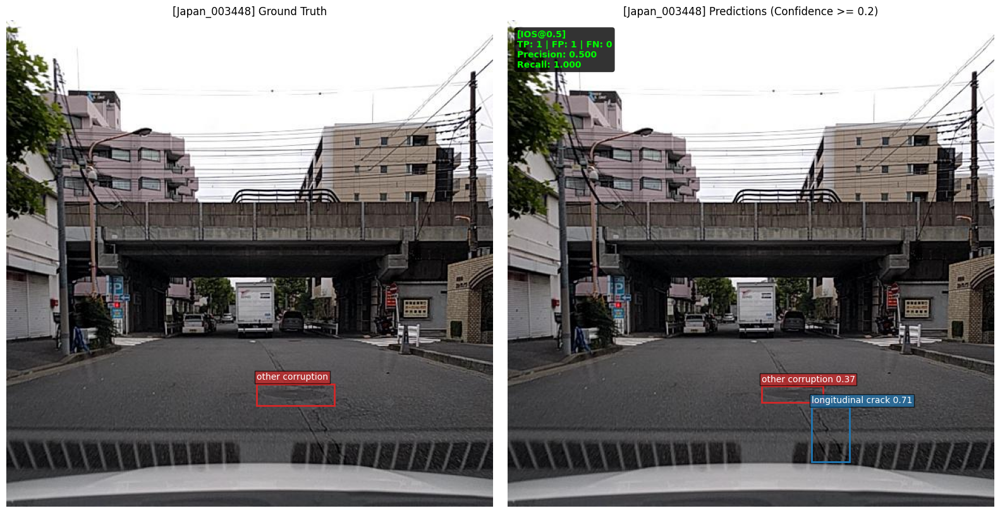


--- Metrics for image: [United_States_001180]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       3 |    1 |    2 |    0 |      0.3333 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


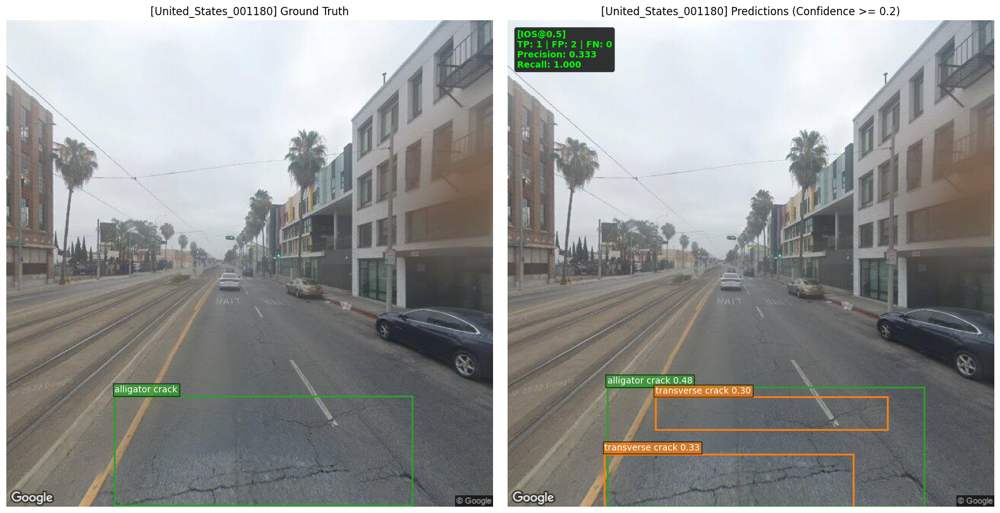


--- Metrics for image: [United_States_001974]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       3 |    1 |    2 |    0 |      0.3333 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


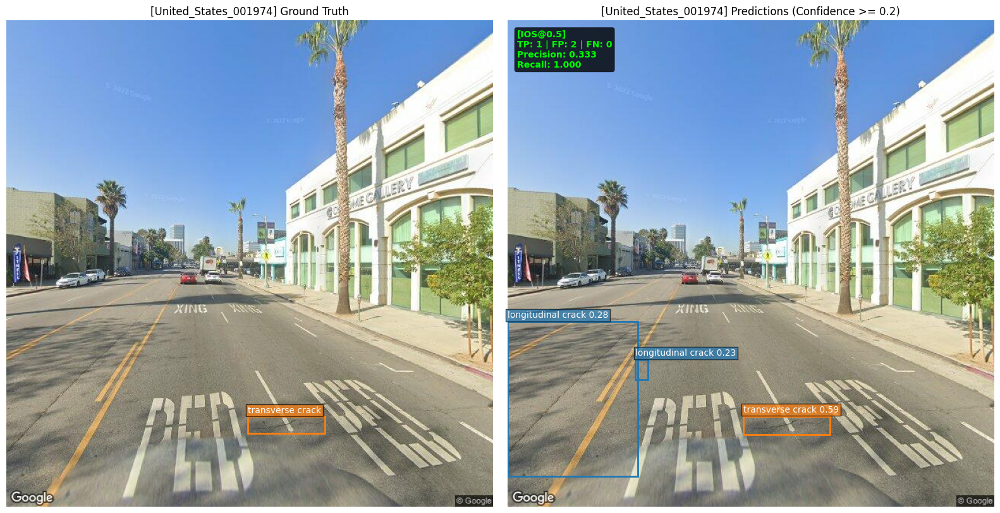


--- Metrics for image: [Japan_003881]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    6 |       1 |    0 |    1 |    6 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


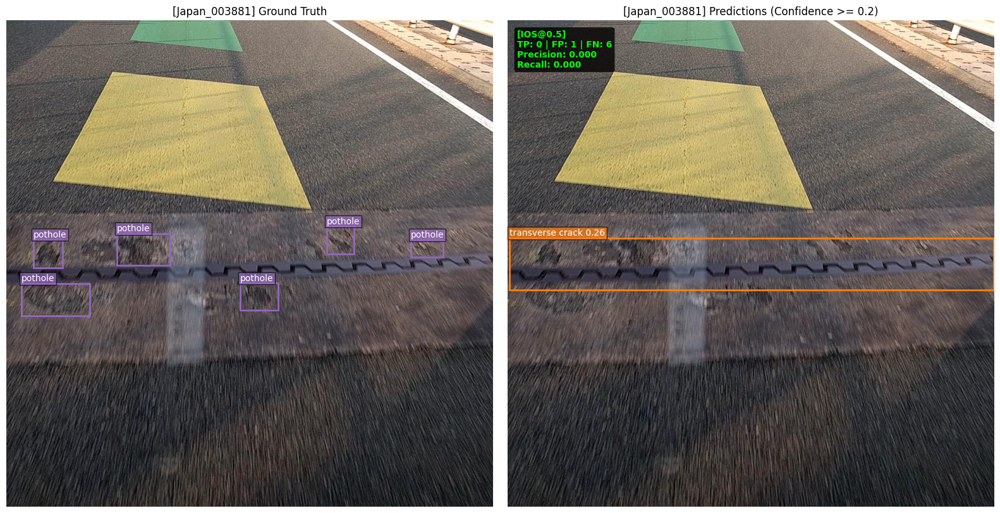

In [33]:
low_precision_images = dataset_evaluator.filter(
    class_names=[
        "longitudinal crack",
        "transverse crack",
        "alligator crack",
        "other corruption",
        "pothole",
    ],
    model_confidence_threshold=0.2,
    metric="precision",
    eq="<",
    class_confidence_threshold=0.5,
)

low_precision_images.plot(
    num_samples=10,
    confidence_threshold=0.2,
    show_stats=True
)

In [34]:
poor_localization = dataset_evaluator.filter(
    class_names=[
        "longitudinal crack",
        "transverse crack",
        "alligator crack",
        "other corruption",
        "pothole",
    ],
    model_confidence_threshold=0.2,
    metric="mean_iou",
    eq="<",
    class_confidence_threshold=0.9,
)

poor_localization.plot(
    num_samples=5,
    confidence_threshold=0.2,
)

Filter matched 0 / 5758 images.


Evaluating (IOS): 0img [00:00, ?img/s]

No image objects available to plot.


Filter matched 192 / 5758 images.
Number of images with >= 2 FP potholes: 192

--- Metrics for image: [China_Drone_000878] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


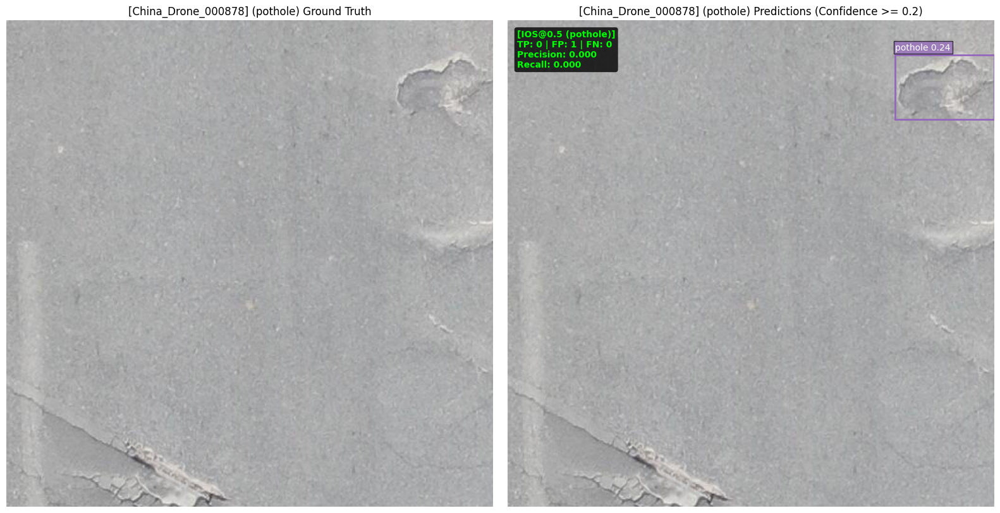


--- Metrics for image: [China_Drone_001270] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


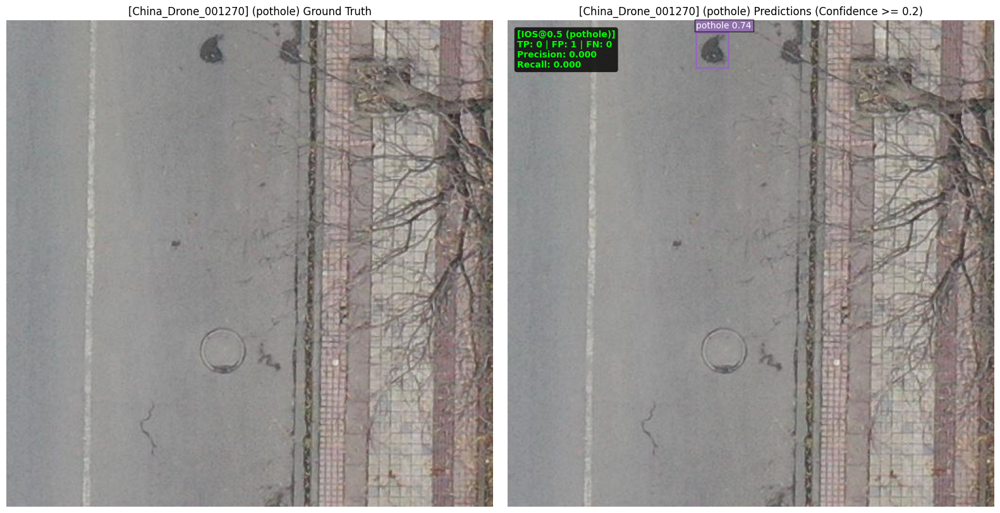


--- Metrics for image: [China_Drone_001348] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


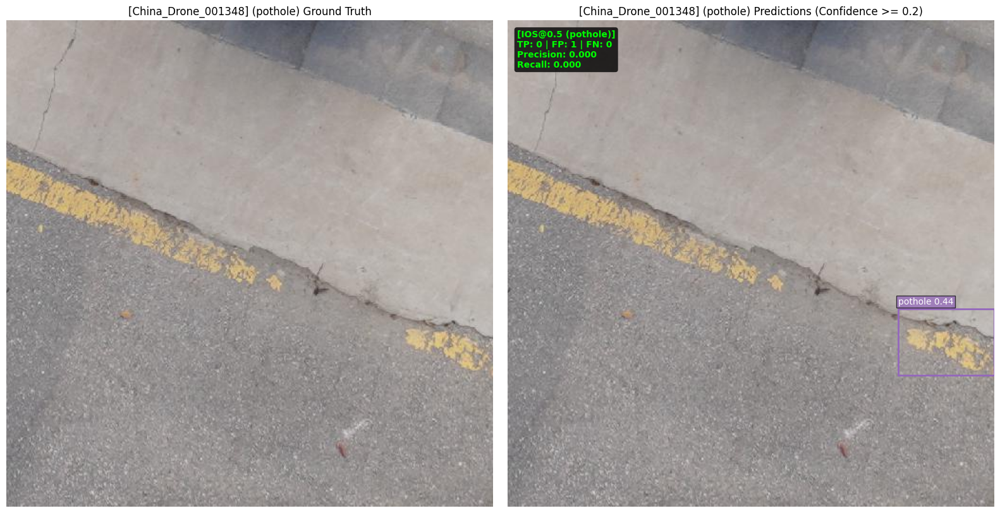


--- Metrics for image: [China_Drone_001487] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


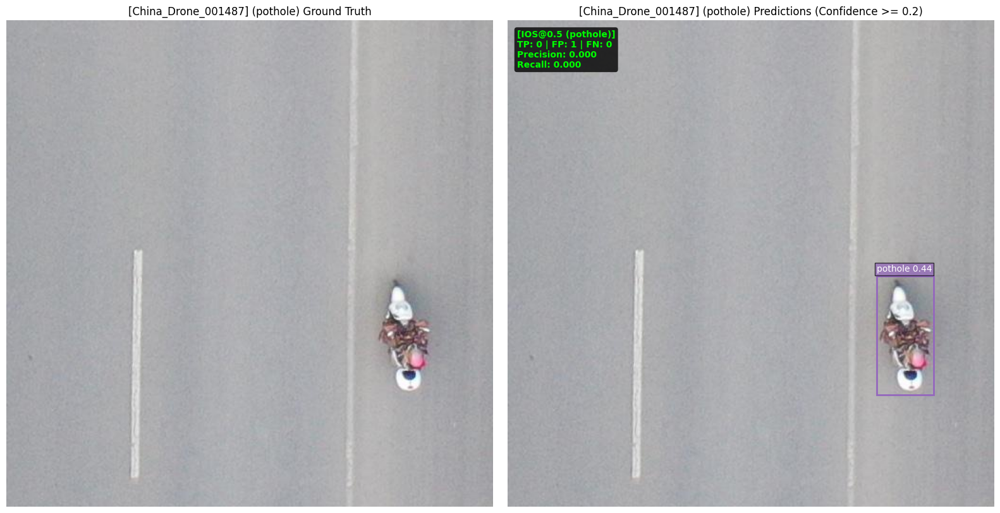


--- Metrics for image: [China_Drone_001761] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


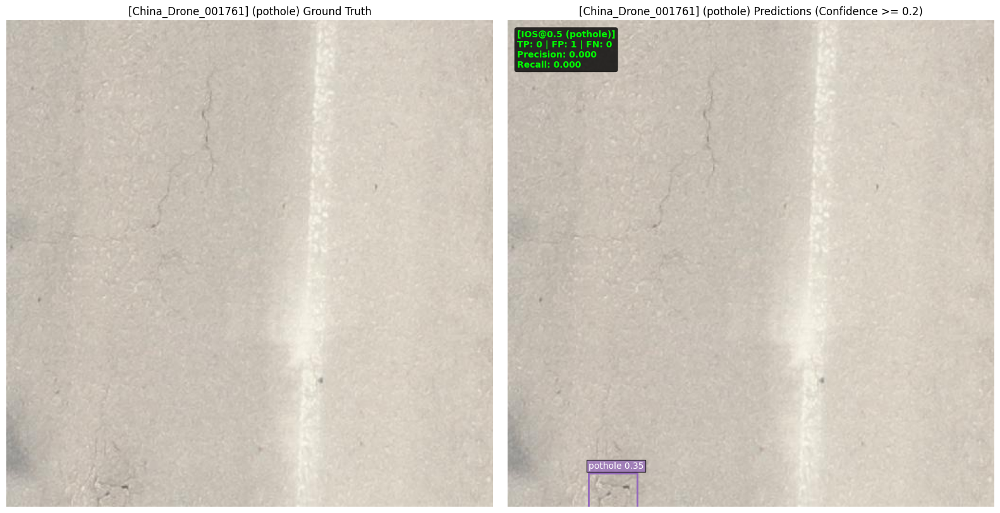


--- Metrics for image: [China_MotorBike_001236] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    2 |       3 |    2 |    1 |    0 |      0.6667 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


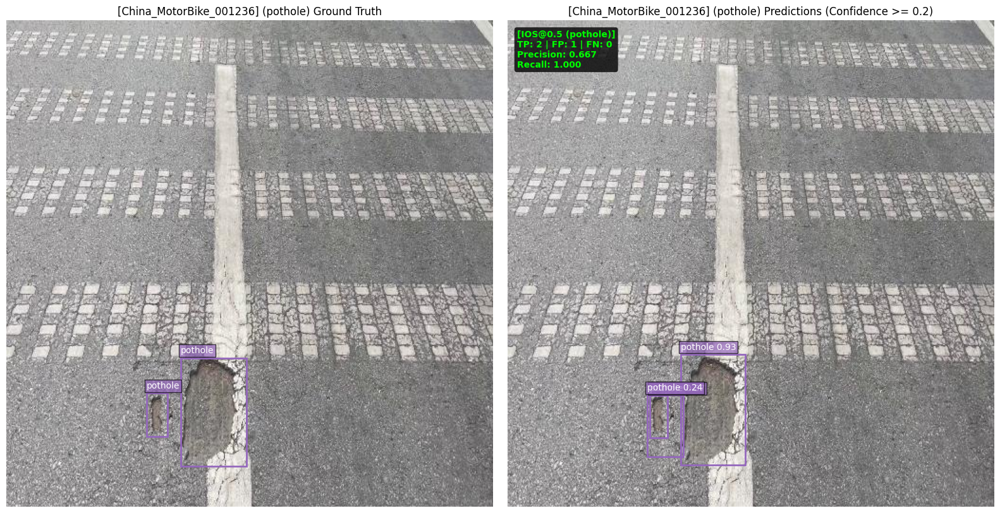


--- Metrics for image: [China_MotorBike_001380] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


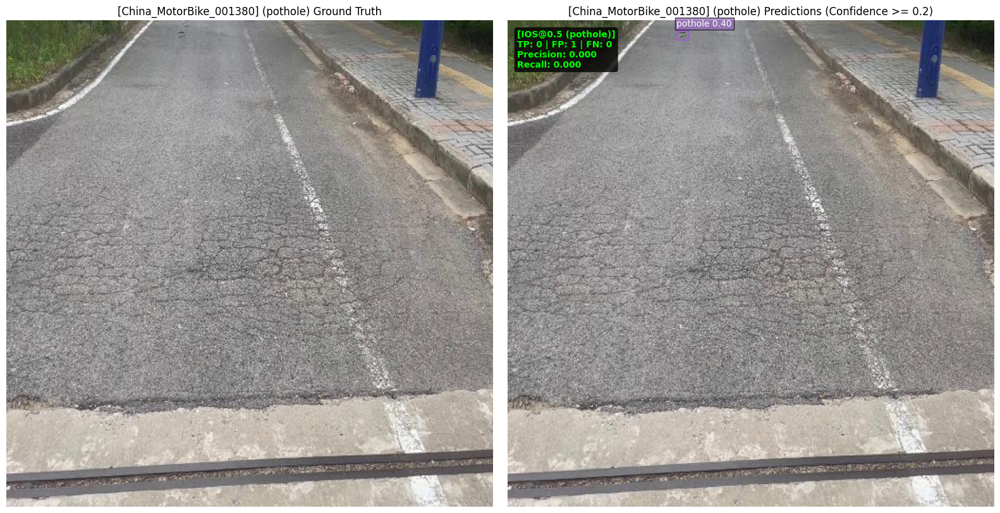


--- Metrics for image: [Czech_000127] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


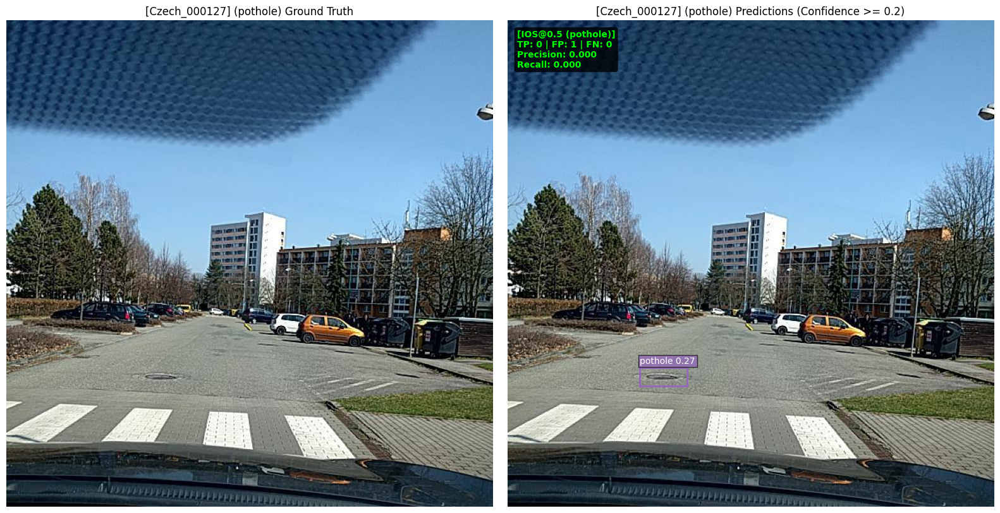


--- Metrics for image: [Czech_000462] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


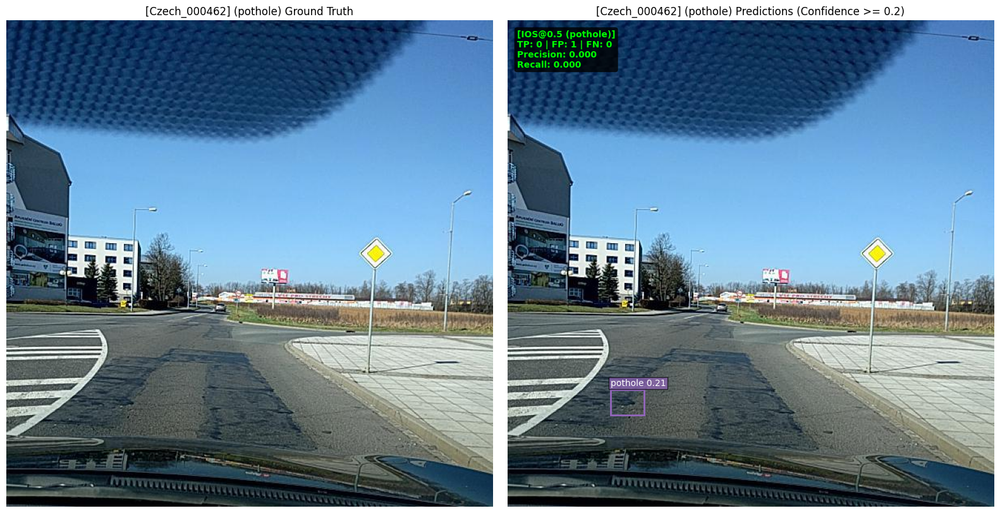


--- Metrics for image: [Czech_000786] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


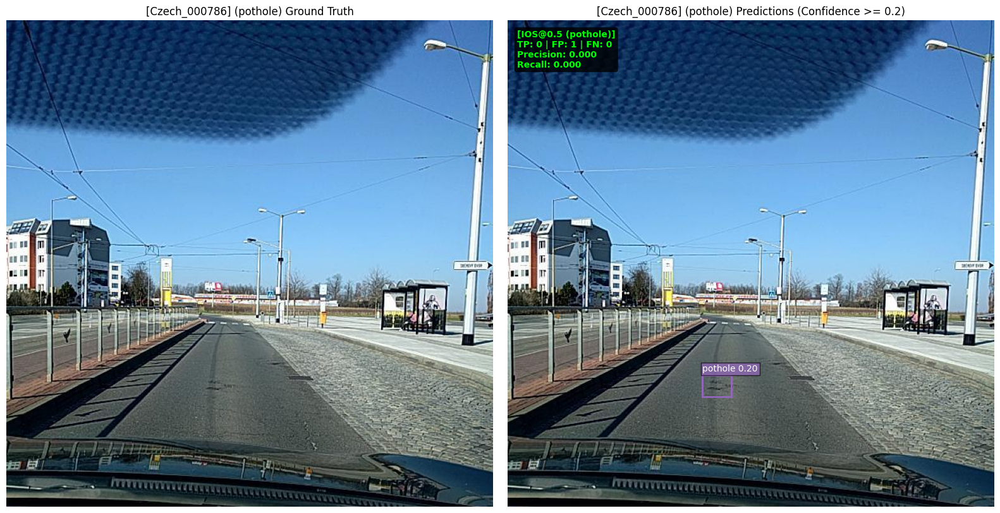

In [35]:
pothole_fp = dataset_evaluator.filter(
    class_names="pothole",
    model_confidence_threshold=0.2,
    metric="fp",
    eq=">=",
    class_confidence_threshold=1,
)
print(f"Number of images with >= 2 FP potholes: {len(pothole_fp.all_image_object)}")
pothole_fp.plot(
    num_samples=10,
    confidence_threshold=0.2,
    class_names="pothole",
    random_sample=False,
    show_stats=True
)


Filter matched 826 / 5758 images.
Images with >= 2 ghost cracks: 826

--- Metrics for image: [United_States_000850] (longitudinal crack)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       2 |    1 |    1 |    0 |         0.5 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


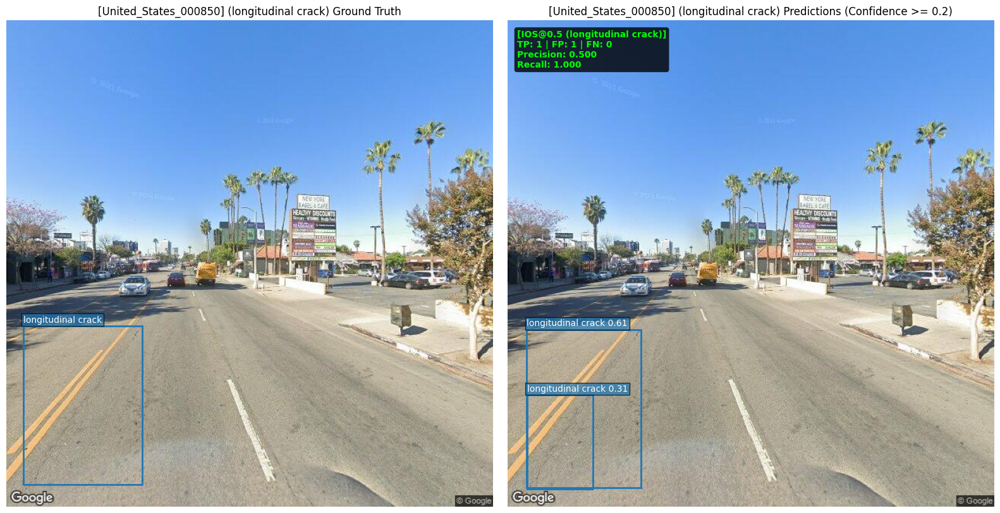


--- Metrics for image: [Japan_003797] (longitudinal crack)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       2 |    1 |    1 |    0 |         0.5 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


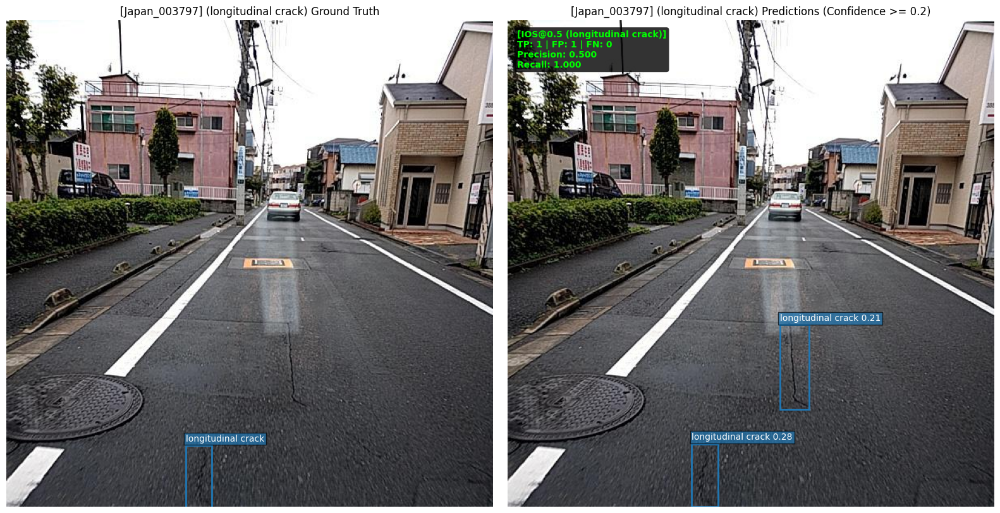


--- Metrics for image: [Norway_000306] (longitudinal crack)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    6 |       5 |    4 |    1 |    2 |         0.8 |   0.6667 |
+------------------+------+---------+------+------+------+-------------+----------+


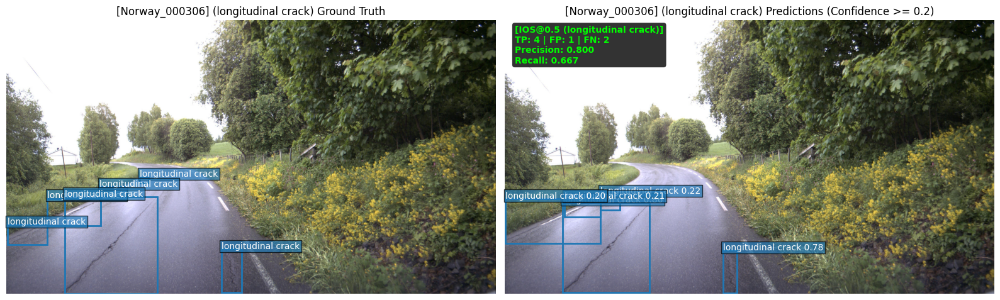


--- Metrics for image: [China_MotorBike_001681] (longitudinal crack)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    5 |       4 |    3 |    1 |    2 |        0.75 |      0.6 |
+------------------+------+---------+------+------+------+-------------+----------+


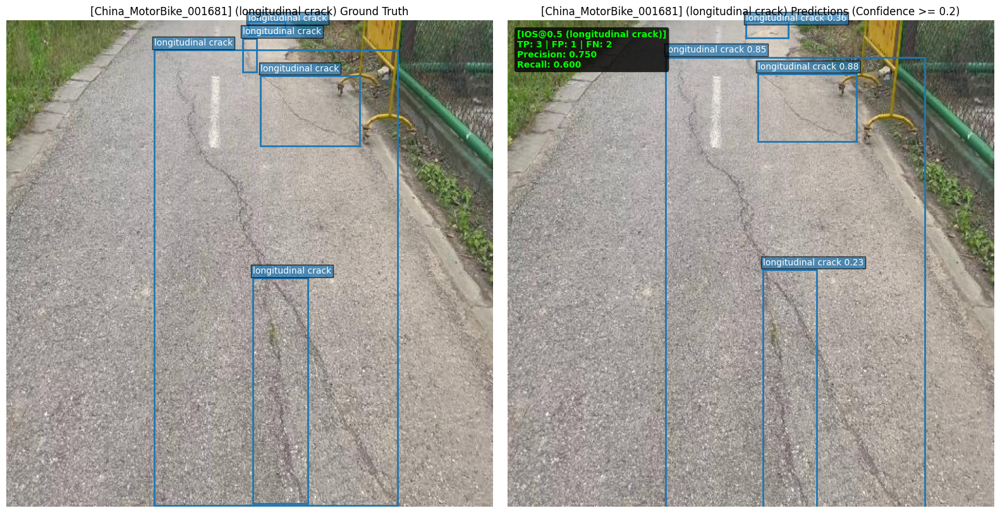


--- Metrics for image: [United_States_003981] (longitudinal crack)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       3 |    1 |    2 |    0 |      0.3333 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


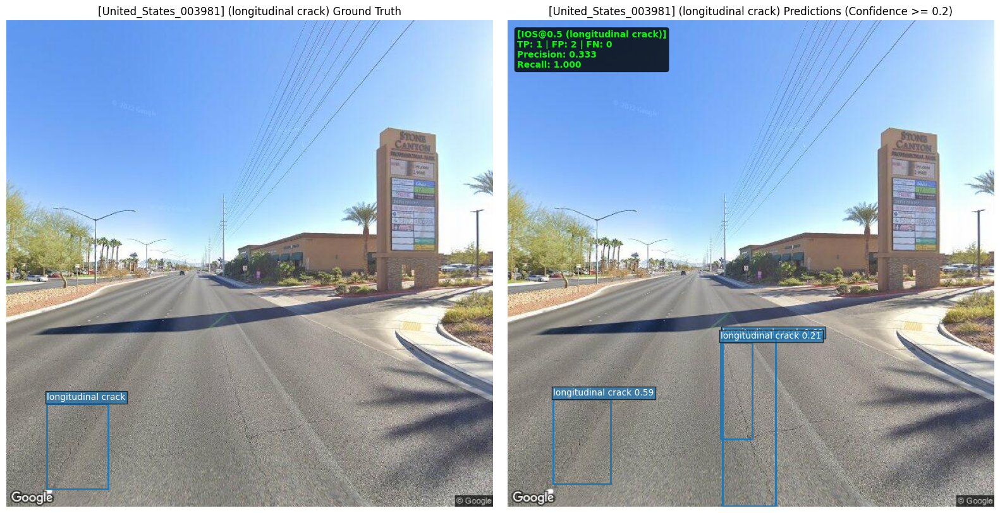

In [36]:
# Find images with 2 or more false positive longitudinal cracks
ghost_cracks = dataset_evaluator.filter(
    class_names="longitudinal crack",
    model_confidence_threshold=0.2,
    metric="fp",
    eq=">=",
    class_confidence_threshold=1
)

print(f"Images with >= 2 ghost cracks: {len(ghost_cracks.all_image_object)}")

# Plot 3 samples to see what road feature fooled the model
ghost_cracks.plot(
    num_samples=5,
    confidence_threshold=0.2,
    class_names="longitudinal crack",
    show_stats=True
)

Filter matched 218 / 5758 images.
Images with >= 2 missed cracks: 218

--- Metrics for image: [China_MotorBike_001657] (longitudinal crack)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    4 |       3 |    2 |    1 |    2 |      0.6667 |      0.5 |
+------------------+------+---------+------+------+------+-------------+----------+


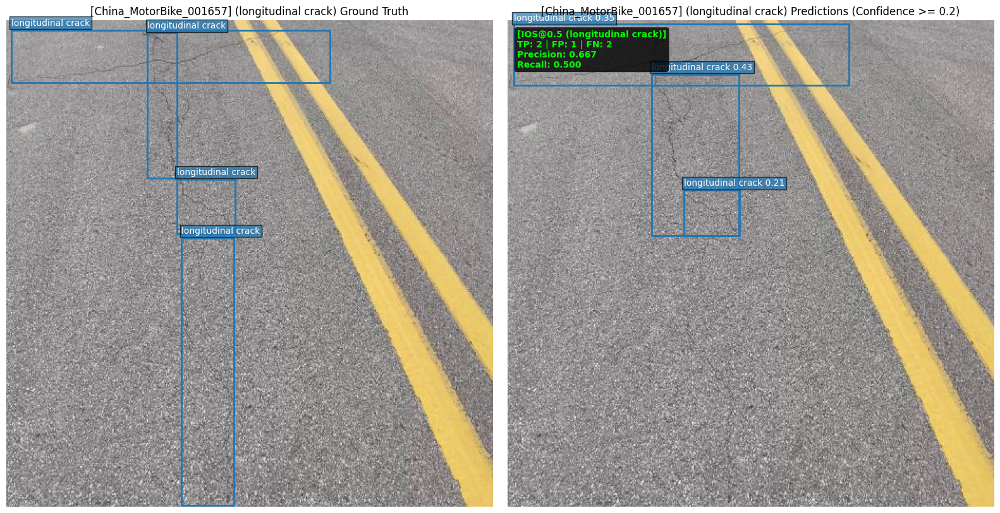


--- Metrics for image: [Norway_000645] (longitudinal crack)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |   10 |       4 |    4 |    0 |    6 |           1 |      0.4 |
+------------------+------+---------+------+------+------+-------------+----------+


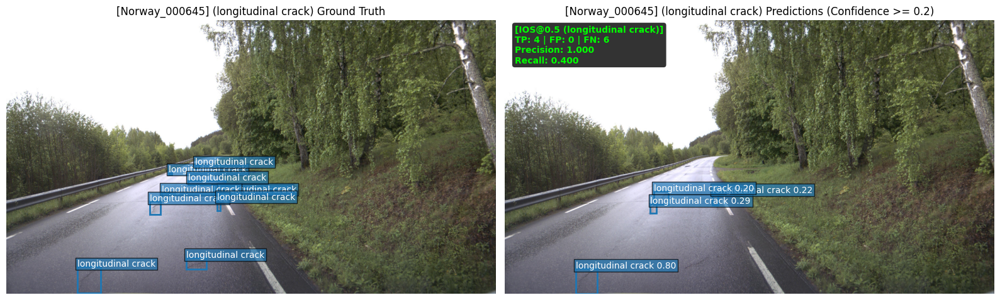


--- Metrics for image: [Japan_011697] (longitudinal crack)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    3 |       2 |    0 |    2 |    3 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


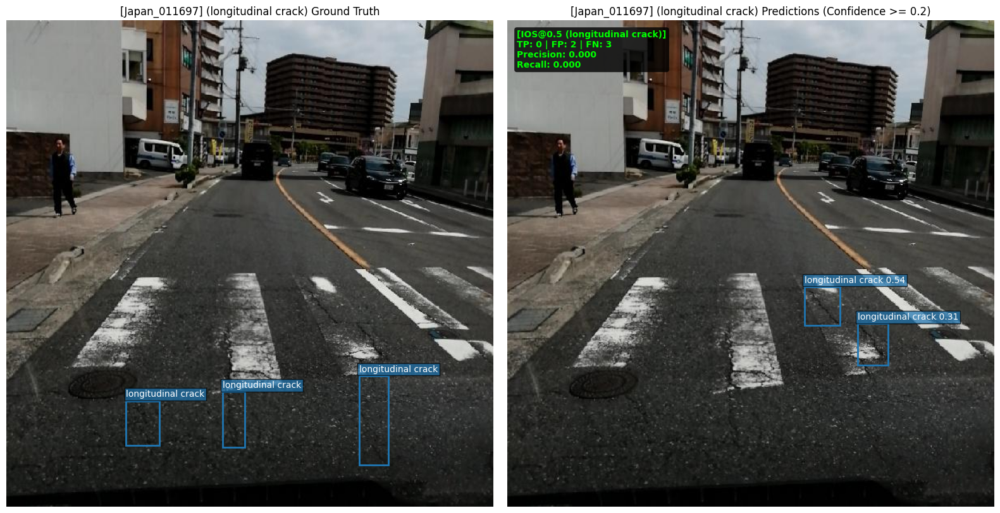


--- Metrics for image: [Norway_005105] (longitudinal crack)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    4 |       2 |    2 |    0 |    2 |           1 |      0.5 |
+------------------+------+---------+------+------+------+-------------+----------+


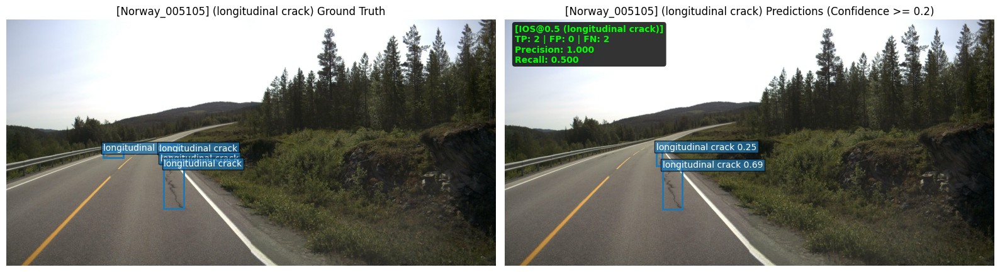


--- Metrics for image: [Norway_001300] (longitudinal crack)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    2 |       1 |    0 |    1 |    2 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


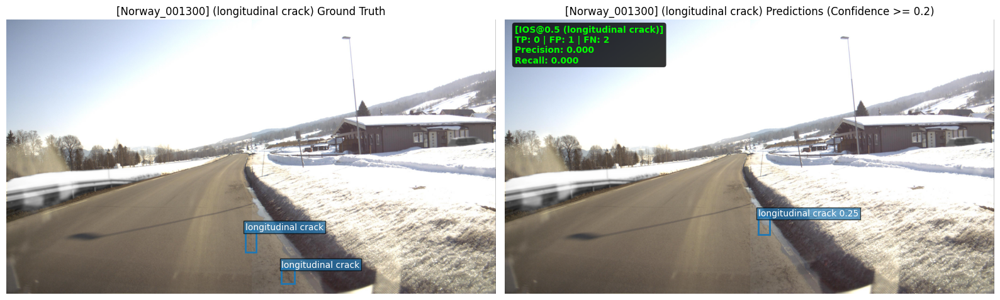

In [37]:
# Find images with 2 or more missed longitudinal cracks
missed_cracks = dataset_evaluator.filter(
    class_names="longitudinal crack",
    model_confidence_threshold=0.2,
    metric="fn",
    eq=">=",
    class_confidence_threshold=2
)

print(f"Images with >= 2 missed cracks: {len(missed_cracks.all_image_object)}")

# Plot 3 samples to see why they were missed (low contrast, far distance, etc.)
missed_cracks.plot(
    num_samples=5,
    confidence_threshold=0.2,
    class_names="longitudinal crack",
    show_stats=True
)

Filter matched 855 / 5758 images.
Images with poor transverse crack F1: 855

--- Metrics for image: [Norway_005719] (transverse crack)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    2 |       2 |    1 |    1 |    1 |         0.5 |      0.5 |
+------------------+------+---------+------+------+------+-------------+----------+


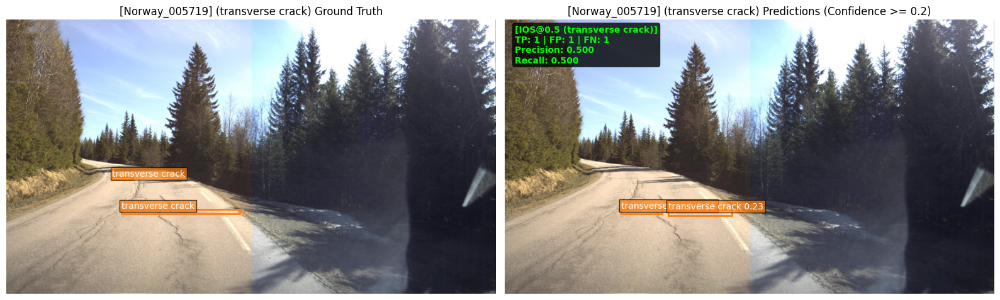


--- Metrics for image: [China_Drone_001625] (transverse crack)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    2 |       3 |    2 |    1 |    0 |      0.6667 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


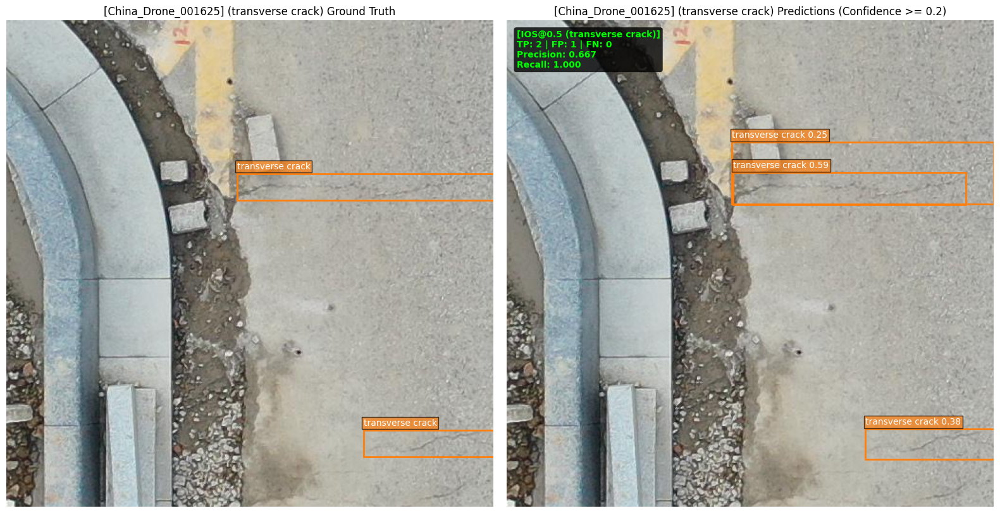


--- Metrics for image: [Japan_009174] (transverse crack)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    3 |       1 |    1 |    0 |    2 |           1 |   0.3333 |
+------------------+------+---------+------+------+------+-------------+----------+


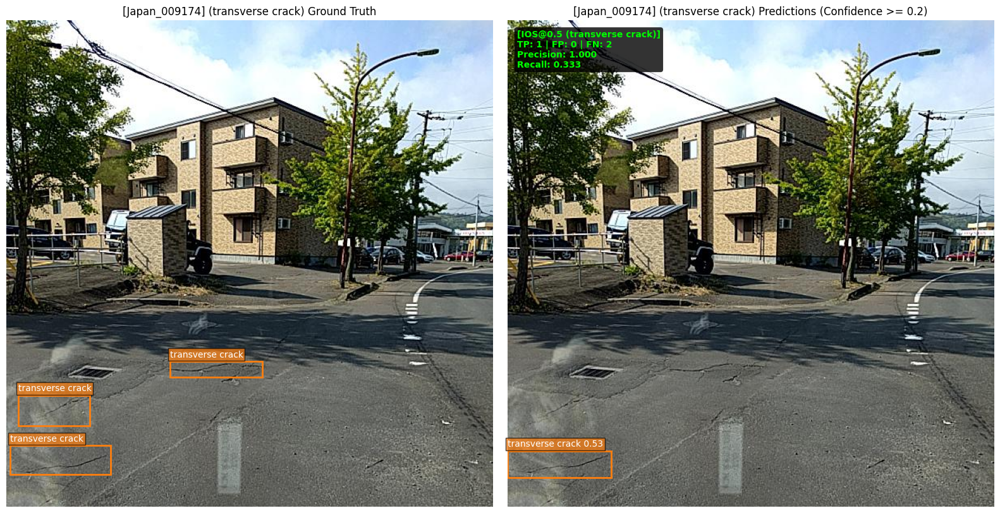


--- Metrics for image: [Japan_005578] (transverse crack)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    6 |       2 |    2 |    0 |    4 |           1 |   0.3333 |
+------------------+------+---------+------+------+------+-------------+----------+


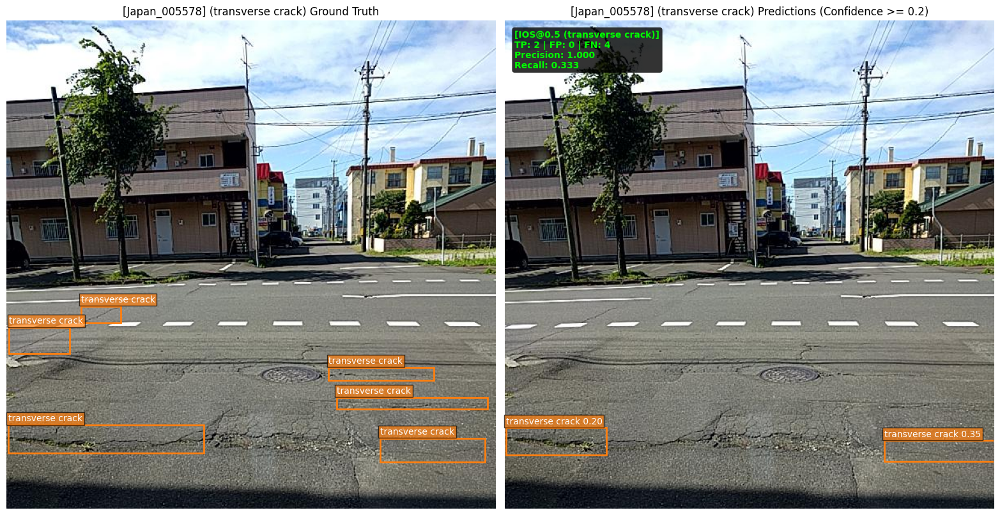


--- Metrics for image: [Japan_011685] (transverse crack)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       2 |    1 |    1 |    0 |         0.5 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


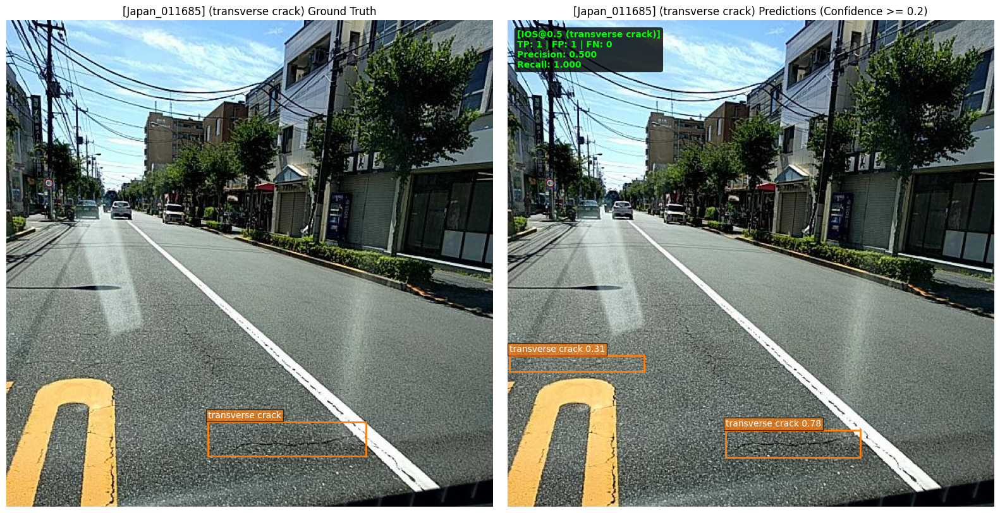

In [38]:
# Find images where transverse crack F1 score failed (< 0.40)
bad_transverse = dataset_evaluator.filter(
    class_names="transverse crack",
    model_confidence_threshold=0.2,
    metric="f1",
    eq="<",
    class_confidence_threshold=1
)

print(f"Images with poor transverse crack F1: {len(bad_transverse.all_image_object)}")

# Plot 3 samples to see if the model confused them with longitudinal cracks
bad_transverse.plot(
    num_samples=5,
    confidence_threshold=0.2,
    class_names="transverse crack",
    show_stats=True
)